# Experiment 8: Implement LeNet for Image Classification

**Aim:** Implement the classic LeNet-5 convolutional network (LeCun et al., 1998) and use it to classify handwritten digits from the MNIST dataset.

**Dataset:** MNIST - 60,000 training and 10,000 test grayscale images of size 28x28 (digits 0-9).

**Architecture (LeNet-5):**

| Layer | Details | Output |
|---|---|---|
| Input | 28x28 image zero-padded to 32x32 | 32x32x1 |
| C1 | Conv 6 filters, 5x5, tanh | 28x28x6 |
| S2 | Average pooling 2x2 | 14x14x6 |
| C3 | Conv 16 filters, 5x5, tanh | 10x10x16 |
| S4 | Average pooling 2x2 | 5x5x16 |
| C5/F5 | Flatten -> Dense 120, tanh | 120 |
| F6 | Dense 84, tanh | 84 |
| Output | Dense 10, softmax | 10 |

In [1]:
# !pip install tensorflow matplotlib scikit-learn   # uncomment if running on a fresh machine
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

tf.random.set_seed(42); np.random.seed(42)
EPOCHS = 10
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Load and preprocess the data
Pixels are scaled to [0, 1]; a channel axis is added. The 28x28 images are zero padded to 32x32 so they match LeNet's original input size.

Train: (60000, 32, 32, 1) (60000,)  Test: (10000, 32, 32, 1) (10000,)


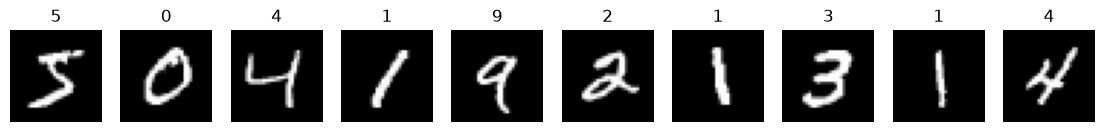

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
x_train = np.pad(x_train, ((0,0),(2,2),(2,2)))[..., None]
x_test  = np.pad(x_test,  ((0,0),(2,2),(2,2)))[..., None]
print("Train:", x_train.shape, y_train.shape, " Test:", x_test.shape, y_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].squeeze(), cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")
plt.show()

## 2. Build the LeNet-5 model

In [3]:
def build_lenet(input_shape=(32, 32, 1), num_classes=10):
    return keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(6, 5, activation="tanh"),          # C1
        layers.AveragePooling2D(2),                       # S2
        layers.Conv2D(16, 5, activation="tanh"),          # C3
        layers.AveragePooling2D(2),                       # S4
        layers.Flatten(),
        layers.Dense(120, activation="tanh"),             # C5
        layers.Dense(84, activation="tanh"),              # F6
        layers.Dense(num_classes, activation="softmax"),  # output
    ], name="LeNet5")

model = build_lenet()
model.summary()

Model: "LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Compile and train

In [4]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, validation_split=0.1,
                    epochs=EPOCHS, batch_size=128, verbose=2)

Epoch 1/10


422/422 - 7s - 15ms/step - accuracy: 0.8916 - loss: 0.3712 - val_accuracy: 0.9630 - val_loss: 0.1374


Epoch 2/10


422/422 - 5s - 13ms/step - accuracy: 0.9575 - loss: 0.1416 - val_accuracy: 0.9747 - val_loss: 0.0891


Epoch 3/10


422/422 - 5s - 13ms/step - accuracy: 0.9724 - loss: 0.0914 - val_accuracy: 0.9798 - val_loss: 0.0709


... (10 outputs left out)

Epoch 9/10


422/422 - 5s - 13ms/step - accuracy: 0.9945 - loss: 0.0212 - val_accuracy: 0.9855 - val_loss: 0.0569


Epoch 10/10


422/422 - 5s - 13ms/step - accuracy: 0.9957 - loss: 0.0169 - val_accuracy: 0.9867 - val_loss: 0.0539


## 4. Training curves

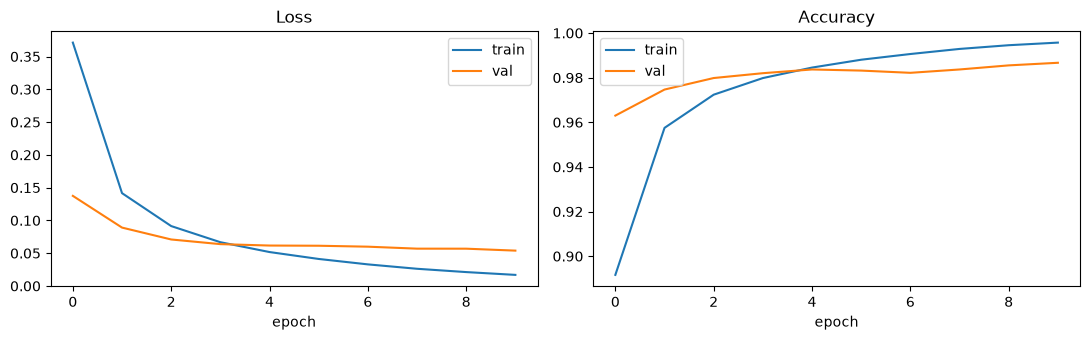

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Evaluation on the test set

Test loss: 0.0504   Test accuracy: 98.49%


              precision    recall  f1-score   support

           0     0.9868    0.9908    0.9888       980
           1     0.9912    0.9947    0.9930      1135
           2     0.9884    0.9884    0.9884      1032
           3     0.9698    0.9871    0.9784      1010
           4     0.9847    0.9837    0.9842       982
           5     0.9875    0.9765    0.9820       892
           6     0.9895    0.9823    0.9859       958
           7     0.9835    0.9844    0.9840      1028
           8     0.9846    0.9846    0.9846       974
           9     0.9830    0.9742    0.9786      1009

    accuracy                         0.9849     10000
   macro avg     0.9849    0.9847    0.9848     10000
weighted avg     0.9849    0.9849    0.9849     10000



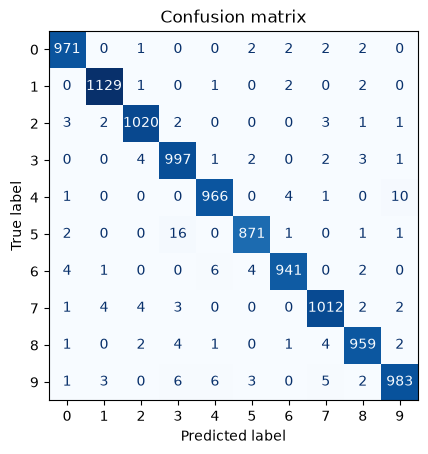

In [6]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}   Test accuracy: {test_acc*100:.2f}%")

y_prob = model.predict(x_test, verbose=0)
y_pred = y_prob.argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix"); plt.show()

## 6. Sample predictions (wrong ones in red)

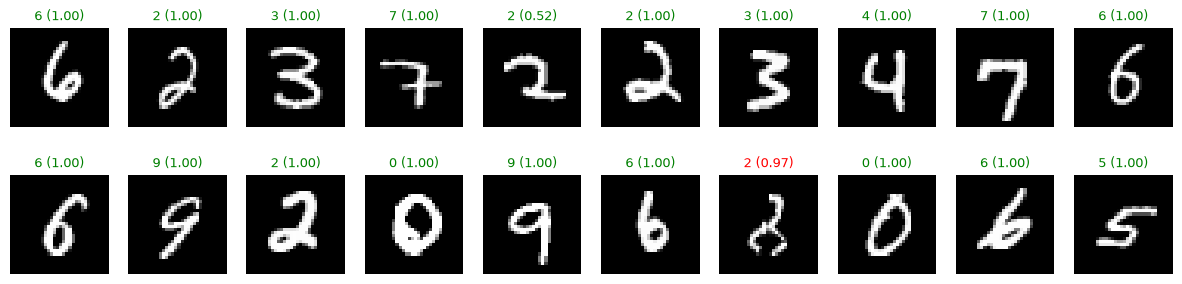

In [7]:
idx = np.random.choice(len(x_test), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(x_test[i].squeeze(), cmap="gray"); ax.axis("off")
    ax.set_title(f"{y_pred[i]} ({y_prob[i].max():.2f})", color="green" if y_pred[i]==y_test[i] else "red", fontsize=9)
plt.show()

## 7. Visualising the learned C1 filters and feature maps

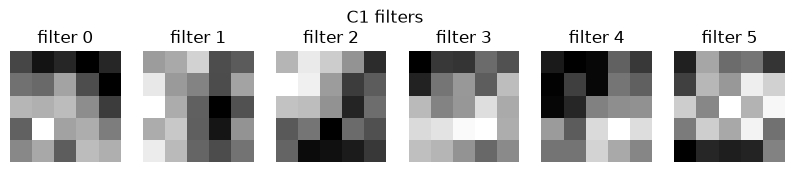

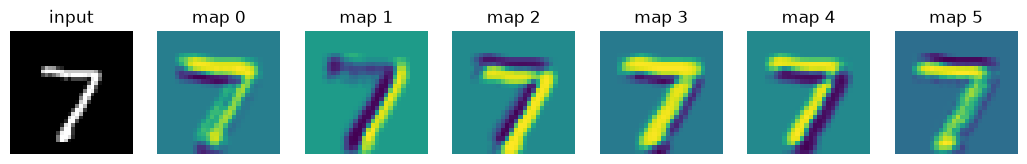

In [8]:
filters = model.layers[0].get_weights()[0]            # (5,5,1,6)
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(filters[:, :, 0, i], cmap="gray"); ax.axis("off"); ax.set_title(f"filter {i}")
plt.suptitle("C1 filters"); plt.show()

feat_model = keras.Model(model.inputs, model.layers[0].output)
fmaps = feat_model.predict(x_test[:1], verbose=0)[0]  # (28,28,6)
fig, axes = plt.subplots(1, 7, figsize=(13, 2))
axes[0].imshow(x_test[0].squeeze(), cmap="gray"); axes[0].set_title("input"); axes[0].axis("off")
for i in range(6):
    axes[i+1].imshow(fmaps[:, :, i], cmap="viridis"); axes[i+1].axis("off"); axes[i+1].set_title(f"map {i}")
plt.show()

## Conclusion
LeNet-5 was implemented from scratch with Keras layers and reached roughly 98-99% test accuracy on MNIST after a few epochs with only ~61k parameters. The convolution + pooling stages learn local stroke/edge detectors (see the C1 filters), and the fully connected layers combine them into a digit decision.